# Laboratorio 2 – Pronóstico de caudal con FDMLP-LSTM

Paper: Jia et al. (2026). *Enhancing streamflow forecasting using an LSTM hybrid model with lightweight frequency-domain feature learning*. Expert Systems With Applications, 297, 129418.

La propuesta central consiste en aplicar, en cada paso de tiempo, una FFT a lo largo del eje de **variables** (no del tiempo), procesar las partes real e imaginaria con un MLP complejo (FDMLP) y regresar al dominio original con la IFFT. La salida se entrega a una LSTM que modela la dependencia temporal. El modelo base del paper es una LSTM sin módulo de aprendizaje de variables.

## Instrucciones de ejecución

```bash
uv sync --locked
uv run --locked python lab02/descargar_archivos.py
cd lab02
uv run --locked python seleccion_lasso.py           # selección de variables (genera resultados/lasso.json)
uv run --locked python entrenar.py --modelo lstm    # modelo base
uv run --locked python entrenar.py --modelo fdmlp   # FDMLP-LSTM (método del paper)
uv run --locked python entrenar.py --modelo mlp     # ablación: mismo modelo sin FFT/IFFT
```

La descarga inicial requiere aproximadamente 5,2 GB. El cuaderno descarga solo los archivos que falten en `Rainfall-Runoff/` y `resultados/`.

Cada entrenamiento guarda los pesos, el historial y las predicciones en `resultados/<modelo>/`. El cuaderno utiliza los historiales y las predicciones, pero no los pesos.

Archivos:
- `datos.py`: carga de `train.h5`/`test.h5`, separación por `split` y normalización.
- `seleccion_lasso.py`: selección de variables con LASSO (Sección 3.1 del paper).
- `modelos.py`: LSTM base, FDMLP y FDMLP-LSTM.
- `entrenar.py`: entrenamiento, parada temprana, métricas y predicciones.

In [ ]:
from descargar_archivos import descargar_archivos

descargar_archivos()

## Diferencias respecto al paper

| Aspecto | Paper | Esta implementación | Motivo |
|---|---|---|---|
| Horizonte | 1, 3 y 5 días (escala diaria) | 48 horas con una capa lineal de 48 salidas | Definido por el laboratorio |
| Datos | Un modelo por estación (~6000 muestras) | Un modelo para 508 cuencas (254 000 ventanas) | Definido por el laboratorio |
| Variables | Estaciones aguas arriba (caudal y precipitación) | Caudal y 11 variables meteorológicas de la misma cuenca | Definido por el dataset |
| Hiperparámetros | Búsqueda aleatoria | Valores óptimos de las Tablas S1 y S5 del material suplementario, sin nueva búsqueda | Costo computacional |
| Operación ⊙ del FDMLP | Descrita como producto elemento a elemento | Producto matricial sobre la dimensión del embedding (como en FreTS) | La Tabla S5 define un tamaño oculto del FDMLP independiente del embedding, lo que solo es posible con un producto matricial |
| Batch / tasa de aprendizaje / épocas máx. | 64 / 1e-4 / 200 | 256 / 1e-3 / 30 | ~40 veces más datos; 30 épocas (~1000 actualizaciones cada una) superan las actualizaciones de 200 épocas del paper (~94 cada una) |
| Parada temprana | Paciencia 5, métrica no indicada | Paciencia 5 sobre el NSE de validación | El paper no especifica la métrica |
| Dropout del FDMLP-LSTM | No reportado | 0.2, igual que la LSTM base | Valor de la Tabla S1 |
| Semillas | No indicado | Una sola (42) | Costo computacional |
| Híbridos AM, CNN y GNN | Sí | No | No requeridos por el laboratorio |
| Ablación sin FFT/IFFT | No | Sí | Requerida por el laboratorio |
| Variables futuras (`y_aux`) | No aplica | No se utilizan | Uso opcional |

## 1. Carga de datos y particiones

In [1]:
import json
import sys
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datos import RUTA_DATOS, CANAL_CAUDAL
from entrenar import metricas
from modelos import MODELOS

sns.set_style("whitegrid")
RESULTADOS = Path("resultados")
NOMBRES = {"persistencia": "Persistencia", "lstm": "LSTM (base)", "fdmlp": "FDMLP-LSTM", "mlp": "MLP-LSTM (ablación, sin FFT)"}

In [2]:
with h5py.File(RUTA_DATOS / "train.h5", "r") as f:
    split = f["split"][:]
    basin = f["basin_id"][:]
    y = f["y"][:]
    ultimo_q = f["X"][:, -1, CANAL_CAUDAL]
    ejemplo_X = f["X"][0]

with h5py.File(RUTA_DATOS / "test.h5", "r") as f:
    basin_test = f["basin_id"][:]
    ultimo_q_test = f["X"][:, -1, CANAL_CAUDAL]

y_test = pd.read_csv(RUTA_DATOS / "test_targets.csv").sort_values("Id").iloc[:, 1:].to_numpy()

val = split == 1
y_val, basin_val = y[val], basin[val]

resumen = pd.DataFrame({
    "muestras": [(split == 0).sum(), val.sum(), len(basin_test)],
    "cuencas": [len(np.unique(basin[split == 0])), len(np.unique(basin_val)), len(np.unique(basin_test))],
}, index=["train", "validación", "test"])
resumen

,muestras,cuencas
train,254000,508
validación,18142,508
test,27983,508


## 2. Preprocesamiento

- Cada variable se estandariza (z-score) con la media y desviación estándar calculadas **solo** con la partición de entrenamiento. Lo mismo se aplica al caudal objetivo, usando los estadísticos del canal de caudal.
- Las predicciones se desnormalizan antes de calcular las métricas, por lo que todo se reporta en mm/h.
- No hay valores faltantes en `X` ni en `y`, por lo que no se requiere imputación.

El caudal está muy concentrado en valores bajos y tiene una cola larga, lo que hace que la MSE y el NSE estén dominados por los eventos altos.

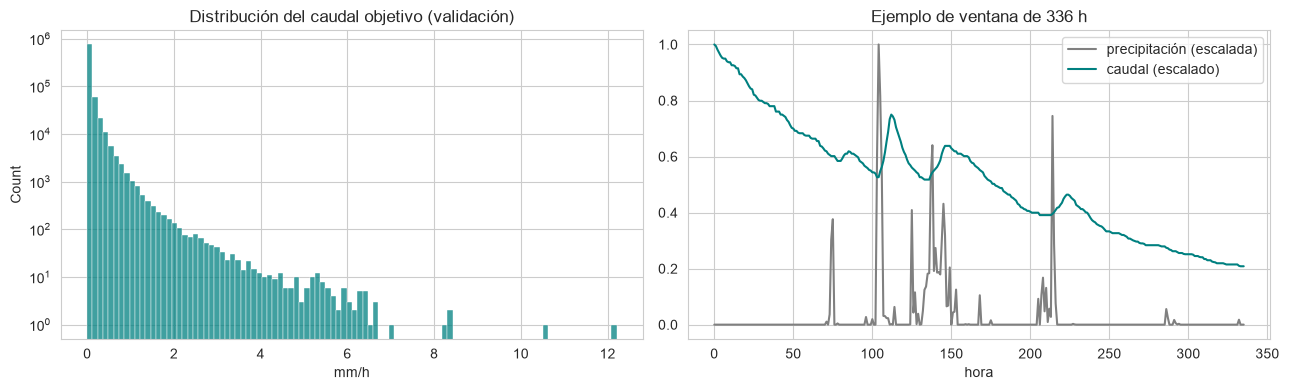

Percentiles del caudal (50, 90, 99, máx): [ 0.0222  0.154   0.7278 12.2085]


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y_val.ravel(), bins=100, ax=axes[0], color="teal")
axes[0].set_yscale("log")
axes[0].set_title("Distribución del caudal objetivo (validación)")
axes[0].set_xlabel("mm/h")

nombres_vars = ["frac. convectiva", "onda larga", "energía pot.", "evap. pot.", "presión", "onda corta",
                "humedad esp.", "temperatura", "precipitación", "viento u", "viento v", "caudal"]
axes[1].plot(ejemplo_X[:, 8] / ejemplo_X[:, 8].max(), label="precipitación (escalada)", color="gray")
axes[1].plot(ejemplo_X[:, CANAL_CAUDAL] / ejemplo_X[:, CANAL_CAUDAL].max(), label="caudal (escalado)", color="teal")
axes[1].set_title("Ejemplo de ventana de 336 h")
axes[1].set_xlabel("hora")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Percentiles del caudal (50, 90, 99, máx): {np.percentile(y_val, [50, 90, 99, 100]).round(4)}")

### Selección de variables con LASSO

Siguiendo la Sección 3.1 del paper, se ajusta una regresión LASSO con validación cruzada de 10 particiones para elegir α (`seleccion_lasso.py`). Como el paper trabaja con series diarias y aquí se tienen ventanas, la respuesta es el caudal medio de las 48 horas futuras y los predictores son los promedios de las últimas 24 horas de cada variable (estandarizados), sobre una muestra de 50 000 ventanas de entrenamiento. Las variables con coeficiente distinto de cero se usan como entrada en los tres modelos.

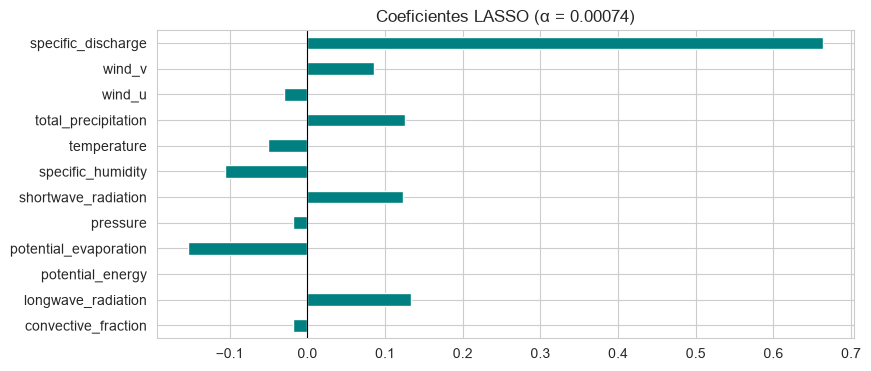

Variables seleccionadas: 11 de 12
Variables descartadas: ['potential_energy']


In [4]:
lasso = json.load(open(RESULTADOS / "lasso.json"))
coef = pd.Series(lasso["coeficientes"])
seleccion = lasso["seleccion"]

plt.figure(figsize=(9, 4))
coef.plot.barh(color=["teal" if c != 0 else "lightgray" for c in coef])
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"Coeficientes LASSO (α = {lasso['alpha']:.5f})")
plt.show()

print(f"Variables seleccionadas: {len(seleccion)} de 12")
print(f"Variables descartadas: {list(coef.index[coef == 0])}")

## 3. Implementación del método

La implementación está en `modelos.py`, con los hiperparámetros de la Tabla S5 del paper. Para cada paso de tiempo $t$, la entrada $x_t \in \mathbb{R}^{11}$ (variables seleccionadas por LASSO) se procesa así:

1. **Embedding:** cada variable se multiplica por un vector aprendible $\phi \in \mathbb{R}^{256}$, obteniendo $H_t \in \mathbb{R}^{11 \times 256}$.
2. **FFT (Ec. 13):** `torch.fft.rfft` a lo largo de las 11 variables, obteniendo 6 componentes de frecuencia complejas.
3. **FDMLP (Ec. 11-12, 14):** dos capas con pesos y sesgos complejos (256 → 256 → 256). Las partes real e imaginaria se manejan por separado:
   $\mathrm{Re}(WX) = W_r X_r - W_i X_i$, $\mathrm{Im}(WX) = W_i X_r + W_r X_i$, y CReLU aplica ReLU a cada parte.
4. **IFFT (Ec. 15):** `torch.fft.irfft` regresa a las 11 variables; se suma la conexión residual y se aplana a 2816 valores por paso.
5. **LSTM:** dos capas de 128 unidades con dropout 0.2; el último estado oculto pasa por una capa lineal de 48 salidas.

La LSTM base usa la configuración de la Tabla S1: dos capas de 256 unidades y dropout 0.2.

Como los pesos del MLP son compartidos por todas las frecuencias, las relaciones entre variables se aprenden a través de la no linealidad CReLU y los sesgos en el dominio de la frecuencia: una modificación en una frecuencia afecta a todas las variables al aplicar la IFFT.

**Ablación:** el modelo `mlp` es idéntico (embedding, dos capas, residual, LSTM) pero sin FFT/IFFT, es decir, el MLP se aplica a cada variable en el dominio original. Así se aísla el aporte del paso por el dominio de la frecuencia.

In [5]:
for nombre in ["lstm", "fdmlp", "mlp"]:
    n = sum(p.numel() for p in MODELOS[nombre](len(seleccion)).parameters())
    print(f"{NOMBRES[nombre]:<20} {n:>8,} parámetros")

LSTM (base)           814,128 parámetros
FDMLP-LSTM           1,910,064 parámetros
MLP-LSTM (ablación, sin FFT) 1,910,064 parámetros


## 4. Entrenamiento y validación

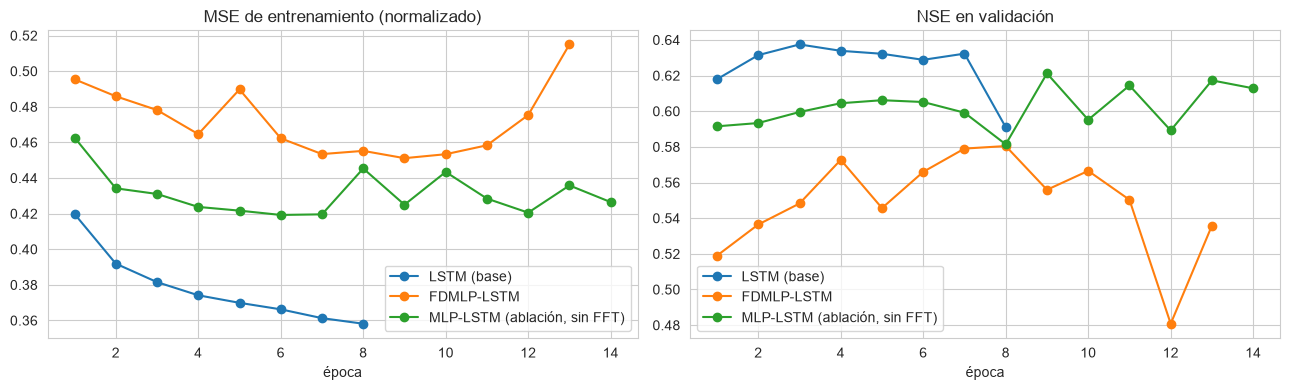

,épocas,mejor época,s/época,inferencia test (s),parámetros
LSTM (base),8.0,3.0,125.4,4.27,814128.0
FDMLP-LSTM,13.0,8.0,1026.7,38.54,1910064.0
"MLP-LSTM (ablación, sin FFT)",14.0,9.0,506.7,21.71,1910064.0


In [6]:
modelos = ["lstm", "fdmlp", "mlp"]
historiales = {m: pd.read_csv(RESULTADOS / m / "historial.csv") for m in modelos}
info = {m: json.load(open(RESULTADOS / m / "info.json")) for m in modelos}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for m in modelos:
    axes[0].plot(historiales[m]["epoca"], historiales[m]["mse_train"], marker="o", label=NOMBRES[m])
    axes[1].plot(historiales[m]["epoca"], historiales[m]["NSE"], marker="o", label=NOMBRES[m])
axes[0].set_title("MSE de entrenamiento (normalizado)")
axes[1].set_title("NSE en validación")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({
    NOMBRES[m]: {
        "épocas": info[m]["epocas_entrenadas"],
        "mejor época": int(historiales[m]["NSE"].idxmax() + 1),
        "s/época": round(info[m]["segundos_por_epoca"], 1),
        "inferencia test (s)": round(info[m]["segundos_inferencia_test"], 2),
        "parámetros": info[m]["parametros"],
    } for m in modelos
}).T

## 5. Métricas

Se reportan NSE, RMSE (mm/h) y R calculados sobre todas las muestras y las 48 horas. Como referencia adicional se incluye la **persistencia** (repetir el último caudal observado durante las 48 horas).

In [7]:
pred_val = {"persistencia": np.repeat(ultimo_q[val][:, None], 48, axis=1)}
pred_test = {"persistencia": np.repeat(ultimo_q_test[:, None], 48, axis=1)}
for m in modelos:
    pred_val[m] = np.load(RESULTADOS / m / "pred_val.npy")
    pred_test[m] = pd.read_csv(RESULTADOS / m / "pred_test.csv").sort_values("Id").iloc[:, 1:].to_numpy()

filas = []
for m in pred_val:
    filas.append({"modelo": NOMBRES[m], "conjunto": "validación", **metricas(y_val, pred_val[m])})
    filas.append({"modelo": NOMBRES[m], "conjunto": "test", **metricas(y_test, pred_test[m])})
tabla = pd.DataFrame(filas).pivot(index="modelo", columns="conjunto").round(4)
tabla.loc[[NOMBRES[m] for m in pred_val]]

NSE               RMSE                  R  \
conjunto                        test validación    test validación    test   
modelo                                                                       
Persistencia                  0.4956     0.3545  0.1188     0.1379  0.7389   
LSTM (base)                   0.6277     0.6375  0.1021     0.1033  0.7925   
FDMLP-LSTM                    0.5540     0.5805  0.1117     0.1111  0.7480   
MLP-LSTM (ablación, sin FFT)  0.5979     0.6212  0.1061     0.1056  0.7733   

                                         
conjunto                     validación  
modelo                                   
Persistencia                     0.6936  
LSTM (base)                      0.7989  
FDMLP-LSTM                       0.7675  
MLP-LSTM (ablación, sin FFT)     0.7884

## 6. Ablación: aporte de la FFT/IFFT

Se comparan FDMLP-LSTM y el mismo modelo sin FFT/IFFT (MLP-LSTM). La mejora relativa se calcula respecto a la LSTM base, como en la Fig. 5 del paper.

In [8]:
base = metricas(y_test, pred_test["lstm"])
mejoras = {}
for m in ["fdmlp", "mlp"]:
    met = metricas(y_test, pred_test[m])
    mejoras[NOMBRES[m]] = {
        "NSE (%)": 100 * (met["NSE"] - base["NSE"]) / base["NSE"],
        "RMSE (%)": 100 * (met["RMSE"] - base["RMSE"]) / base["RMSE"],
        "R (%)": 100 * (met["R"] - base["R"]) / base["R"],
    }
pd.DataFrame(mejoras).T.round(2)

,NSE (%),RMSE (%),R (%)
FDMLP-LSTM,-11.74,9.45,-5.61
"MLP-LSTM (ablación, sin FFT)",-4.76,3.93,-2.42


### Corrida preliminar

Antes de la corrida final se entrenaron los mismos tres modelos con una configuración más pequeña: embedding 16 y capa oculta del FDMLP 16, LSTM de 1 capa con 128 unidades, sin dropout y con las 12 variables (sin LASSO). Sus resultados se guardan en `resultados_v1/`. Con los valores por defecto actuales de los scripts no es posible reproducirla; se incluye solo como evidencia de apoyo.

In [9]:
preliminar = pd.DataFrame({
    NOMBRES[m]: json.load(open(Path("resultados_v1") / m / "info.json")) for m in ["lstm", "fdmlp", "mlp"]
}).T[["parametros", "NSE_val", "RMSE_val", "R_val", "segundos_por_epoca"]]
preliminar.astype(float).round(4)

,parametros,NSE_val,RMSE_val,R_val,segundos_por_epoca
LSTM (base),78896.0,0.6445,0.1023,0.8035,27.2392
FDMLP-LSTM,172160.0,0.6331,0.1039,0.7957,119.7019
"MLP-LSTM (ablación, sin FFT)",172160.0,0.6386,0.1032,0.7992,64.3711


## 7. Análisis de errores

### 7.1 Error según el horizonte de predicción

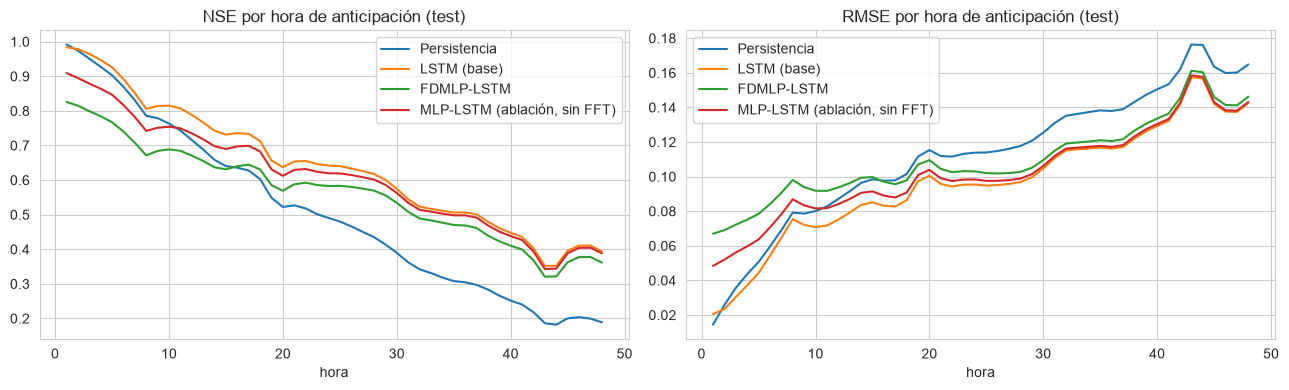

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
horas = np.arange(1, 49)
for m in pred_test:
    nse_h = [metricas(y_test[:, h], pred_test[m][:, h])["NSE"] for h in range(48)]
    rmse_h = [metricas(y_test[:, h], pred_test[m][:, h])["RMSE"] for h in range(48)]
    axes[0].plot(horas, nse_h, label=NOMBRES[m])
    axes[1].plot(horas, rmse_h, label=NOMBRES[m])
axes[0].set_title("NSE por hora de anticipación (test)")
axes[1].set_title("RMSE por hora de anticipación (test)")
for ax in axes:
    ax.set_xlabel("hora")
    ax.legend()
plt.tight_layout()
plt.show()

### 7.2 Desempeño por cuenca

Mediana del NSE por cuenca (test):
Persistencia                    0.4916
LSTM (base)                     0.5488
FDMLP-LSTM                      0.4207
MLP-LSTM (ablación, sin FFT)    0.4913
dtype: float64


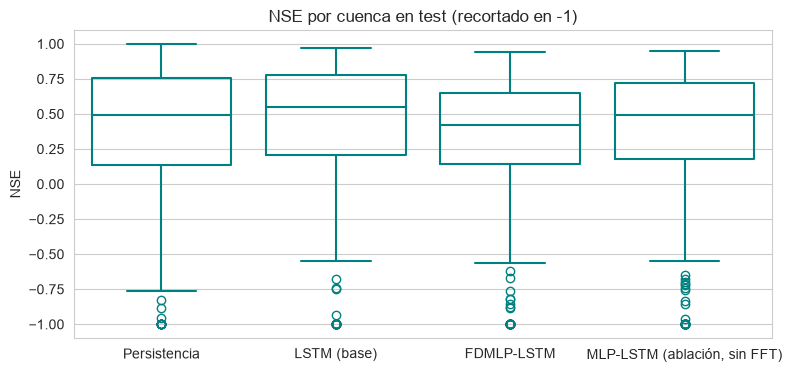

In [11]:
def nse_por_cuenca(y_obs, y_pred, cuencas):
    df = pd.DataFrame({"cuenca": np.repeat(cuencas, 48), "obs": y_obs.ravel(), "pred": y_pred.ravel()})
    df["err2"] = (df["obs"] - df["pred"]) ** 2
    df["var"] = (df["obs"] - df.groupby("cuenca")["obs"].transform("mean")) ** 2
    g = df.groupby("cuenca")[["err2", "var"]].sum()
    return 1 - g["err2"] / g["var"]

nse_cuencas = pd.DataFrame({NOMBRES[m]: nse_por_cuenca(y_test, pred_test[m], basin_test) for m in pred_test})
print("Mediana del NSE por cuenca (test):")
print(nse_cuencas.median().round(4))

plt.figure(figsize=(9, 4))
sns.boxplot(data=nse_cuencas.clip(lower=-1), color="teal", fill=False)
plt.title("NSE por cuenca en test (recortado en -1)")
plt.ylabel("NSE")
plt.show()

### 7.3 Error según la magnitud del caudal

In [12]:
q_obs = y_test.max(axis=1)
umbral = np.percentile(q_obs, 95)
altos = q_obs >= umbral

filas = []
for m in pred_test:
    filas.append({"modelo": NOMBRES[m], "grupo": "caudal alto (≥ p95)", **metricas(y_test[altos], pred_test[m][altos])})
    filas.append({"modelo": NOMBRES[m], "grupo": "resto", **metricas(y_test[~altos], pred_test[m][~altos])})
print(f"Umbral p95 del caudal máximo de cada ventana: {umbral:.4f} mm/h")
pd.DataFrame(filas).pivot(index="modelo", columns="grupo").round(4)

Umbral p95 del caudal máximo de cada ventana: 0.4990 mm/h


NSE                        RMSE  \
grupo                        caudal alto (≥ p95)   resto caudal alto (≥ p95)   
modelo                                                                         
FDMLP-LSTM                               -0.0107  0.7221              0.4718   
LSTM (base)                               0.1479  0.7874              0.4332   
MLP-LSTM (ablación, sin FFT)              0.0892  0.7482              0.4479   
Persistencia                             -0.1866  0.7852              0.5112   

                                                       R          
grupo                          resto caudal alto (≥ p95)   resto  
modelo                                                            
FDMLP-LSTM                    0.0376              0.4087  0.8627  
LSTM (base)                   0.0329              0.4991  0.9050  
MLP-LSTM (ablación, sin FFT)  0.0358              0.4649  0.8864  
Persistencia                  0.0330              0.4029  0.9023

Error relativo mediano del pico en ventanas de caudal alto:
LSTM (base)                    -31.0 %
FDMLP-LSTM                     -49.8 %
MLP-LSTM (ablación, sin FFT)   -40.9 %


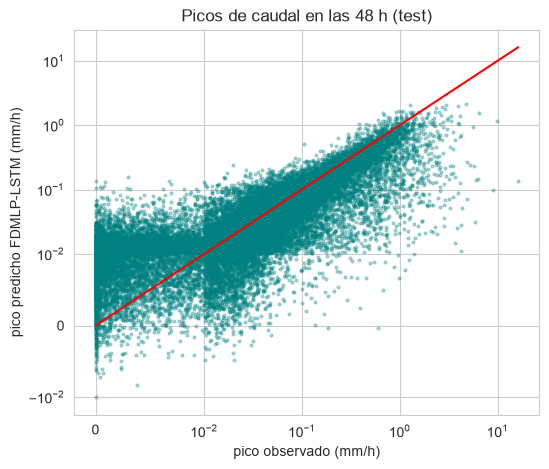

In [13]:
pico_obs = y_test.max(axis=1)
pico_pred = pred_test["fdmlp"].max(axis=1)
print("Error relativo mediano del pico en ventanas de caudal alto:")
for m in ["lstm", "fdmlp", "mlp"]:
    error_pico = 100 * (pred_test[m][altos].max(axis=1) - pico_obs[altos]) / pico_obs[altos]
    print(f"{NOMBRES[m]:<30} {np.median(error_pico):.1f} %")

plt.figure(figsize=(6, 5))
plt.scatter(pico_obs, pico_pred, s=4, alpha=0.3, color="teal")
lim = pico_obs.max()
plt.plot([0, lim], [0, lim], color="red")
plt.xscale("symlog", linthresh=0.01)
plt.yscale("symlog", linthresh=0.01)
plt.xlabel("pico observado (mm/h)")
plt.ylabel("pico predicho FDMLP-LSTM (mm/h)")
plt.title("Picos de caudal en las 48 h (test)")
plt.show()

### 7.4 Ejemplos de hidrogramas

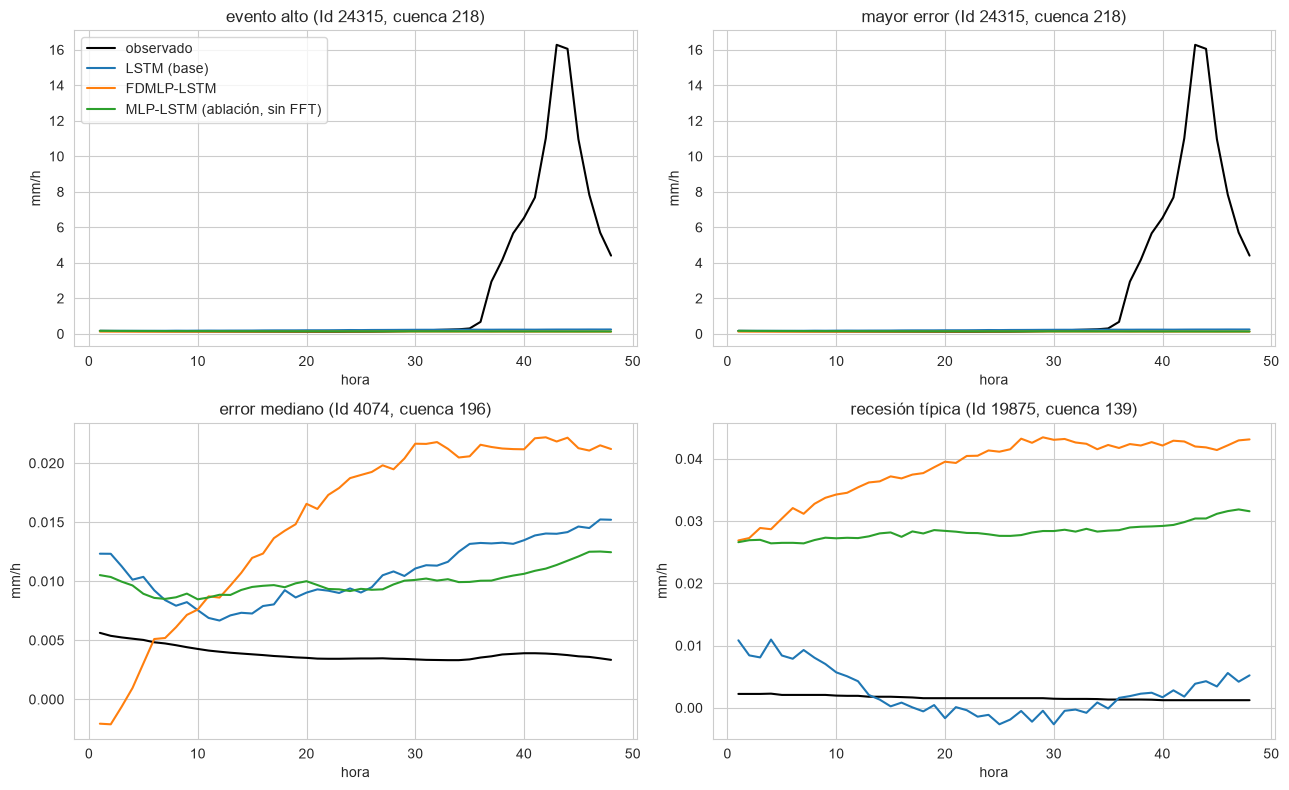

In [14]:
err = ((pred_test["fdmlp"] - y_test) ** 2).mean(axis=1)
ejemplos = {
    "evento alto": np.argmax(np.where(altos, y_test.max(axis=1), 0)),
    "mayor error": np.argmax(err),
    "error mediano": np.argsort(err)[len(err) // 2],
    "recesión típica": np.argsort(np.abs(y_test[:, -1] - y_test[:, 0]))[len(err) // 3],
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (titulo, i) in zip(axes.flatten(), ejemplos.items()):
    ax.plot(horas, y_test[i], color="black", label="observado")
    for m in ["lstm", "fdmlp", "mlp"]:
        ax.plot(horas, pred_test[m][i], label=NOMBRES[m])
    ax.set_title(f"{titulo} (Id {i}, cuenca {basin_test[i]})")
    ax.set_xlabel("hora")
    ax.set_ylabel("mm/h")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## 8. Predicciones para test

In [15]:
final = pd.read_csv(RESULTADOS / "fdmlp" / "pred_test.csv")
referencia = pd.read_csv(RUTA_DATOS / "test_targets.csv", nrows=1)
assert list(final.columns) == list(referencia.columns)
assert len(final) == len(basin_test) and not final.isna().any().any()
final.to_csv("predicciones_test.csv", index=False)
print(final.shape)
final.head()

(27983, 49)


,Id,q_01,q_02,q_03,q_04,q_05,q_06,q_07,q_08,q_09,...,q_39,q_40,q_41,q_42,q_43,q_44,q_45,q_46,q_47,q_48
0,0,0.146669,0.149233,0.150671,0.153543,0.152883,0.154790,0.154852,0.155815,0.154800,...,0.176824,0.178178,0.176416,0.178277,0.178592,0.181097,0.179809,0.183055,0.185477,0.185945
1,1,0.019276,0.020512,0.021477,0.022920,0.022888,0.025101,0.024477,0.025684,0.025212,...,0.011797,0.010951,0.010987,0.010569,0.011805,0.010865,0.011057,0.011676,0.013320,0.013183
2,2,-0.005797,-0.004985,-0.004420,-0.003653,-0.002991,-0.001217,-0.000790,-0.000734,0.000575,...,0.015209,0.015855,0.016314,0.014412,0.015443,0.013784,0.013911,0.014297,0.015425,0.014565
3,3,-0.005658,-0.005278,-0.004978,-0.004137,-0.004059,-0.003207,-0.002646,-0.002473,-0.001743,...,0.005852,0.005118,0.005991,0.005879,0.005488,0.005581,0.005033,0.005864,0.006300,0.006231
4,4,0.004091,0.005109,0.003591,0.006016,0.006298,0.004778,0.004691,0.002946,0.004491,...,0.007232,0.007840,0.008691,0.008269,0.008085,0.006494,0.007731,0.007265,0.007361,0.005837


## 9. Conclusiones y limitaciones

**Resultados**

- Los tres modelos superan a la persistencia (NSE test 0.496). El mejor es la LSTM base (NSE test 0.628), seguida de MLP-LSTM (0.598) y FDMLP-LSTM (0.554).
- No se reproduce la mejora reportada en el paper: FDMLP-LSTM queda 11.7 % por debajo de la LSTM en NSE y 9.5 % por encima en RMSE. En la mediana por cuenca (0.42) incluso queda por debajo de la persistencia (0.49).
- La ablación indica que, con estos datos, la FFT sobre el eje de variables no aporta: quitarla mejora el NSE de 0.554 a 0.598. La corrida preliminar con embedding 16 y las 12 variables (sección 6) dio el mismo orden (LSTM 0.645 > MLP-LSTM 0.639 > FDMLP-LSTM 0.633 en validación). Además, esa configuración pequeña obtuvo mejor NSE de validación en los tres modelos, sobre todo FDMLP-LSTM (0.633 frente a 0.581). Esto sugiere que los hiperparámetros del material suplementario, elegidos para series diarias de una sola estación, no se trasladan bien a este problema.

**Posibles causas**

- En el paper las variables son estaciones aguas arriba de una misma red, con una relación física entre ellas. Aquí son 11 series meteorológicas y de caudal de naturaleza distinta y con poca correlación entre sí (|r| medio de 0.21). Además, el orden de las variables es arbitrario, por lo que las "frecuencias" a lo largo de ese eje tienen poco significado físico.
- Las variables más informativas son el caudal pasado y la precipitación. La LSTM las recibe directamente, mientras que FDMLP-LSTM recibe una entrada de 2816 dimensiones y debe recuperarlas.
- La mayor diferencia aparece en las primeras horas: en la hora 1, el NSE en test es 0.98 para la LSTM y 0.83 para FDMLP-LSTM, mientras que en la hora 48 ambos quedan cerca (0.39 y 0.36). Esto indica que, al mezclar las variables, FDMLP-LSTM aprovecha peor el último caudal observado, que es el predictor más fuerte.
- El MSE de entrenamiento de FDMLP-LSTM sube en algunas épocas (5, 12 y 13), lo que sugiere que lr = 1e-3 resulta alto para esta arquitectura. No se ajustó, para comparar todos los modelos en las mismas condiciones.

**Eficiencia**

- FDMLP-LSTM tarda unos 1027 s por época y la LSTM 125 s (unas 8 veces más). En inferencia la diferencia es de 9 veces. La mitad del costo adicional proviene de la parte compleja: MLP-LSTM tarda 507 s por época.

**Caudales altos**

- En el 5 % de ventanas con caudal más alto, todos los modelos rinden mal (NSE ≤ 0.15) y subestiman el pico: la mediana del error es de −31 % (LSTM), −41 % (MLP-LSTM) y −50 % (FDMLP-LSTM). La pérdida MSE, con caudales muy asimétricos y normalización z-score global, favorece los caudales bajos, que son la mayoría.
- Algunas predicciones son ligeramente negativas, porque no se impone ninguna restricción de no negatividad.

**Limitaciones**

- Se usó una sola semilla (42). Entre épocas consecutivas, el NSE de validación varía entre 0.01 y 0.03, por lo que la diferencia entre LSTM y MLP-LSTM no es concluyente. La de FDMLP-LSTM (≈ 0.07 en test) sí supera esa variación.
- Se entrenó un solo modelo para las 508 cuencas, mientras que el paper entrena un modelo por estación. La mediana del NSE por cuenca es menor que el NSE global porque, al calcularlo con todas las muestras juntas, la varianza incluye las diferencias entre cuencas.
- Ningún modelo alcanzó el límite de 30 épocas (la parada temprana actuó entre las épocas 8 y 14), por lo que ese límite no restringió los resultados.
- No se implementaron AM-LSTM, CNN-LSTM ni GNN-LSTM.